# Stage 5 — Data Preparation for Modelling

## Overview

This project has two phases, each in its own folder:

| Stage | Notebook | Answers |
|---|---|---|
| 1–4. Analytics | `01 Analysis/` | Where does default risk concentrate? |
| 5. Data Preparation *(this file)* | `05_data_preparation.ipynb` | Is the data ready for modeling, free of leakage? |
| 6. PD Model | `06_PD_model.ipynb` | What is the probability a borrower defaults? |
| 7. LGD Model | `07_LGD_model.ipynb` | If a loan defaults, what fraction of the balance is lost? |
| 8. EAD Model | `08_EAD_model.ipynb` | How much principal is outstanding at the moment of default? |
| 9. Portfolio EL | `09_Expected_Loss_portfolio.ipynb` | What is the expected dollar loss across the full portfolio? |

Phase 1 (stages 1–4) answered where risk concentrates. Phase 2 (stages 5–9) quantifies it in dollar terms: **EL = PD × LGD × EAD**.

---

## Introduction

The cleaned Lending Club dataset contains **1,371,165 loans across 20 variables**, ready for analysis. But ready for analysis is not the same as ready for modeling. Before training any machine learning model, four critical decisions must be made — and getting any of them wrong silently corrupts every result that follows.

**Decision 1 — Leakage removal.** One column in the dataset is only observable *after* the loan outcome is known: `total_pymnt` (total amount repaid), which accumulates over the life of the loan. Including it as a feature would let the model "see the future" during training, inflating performance metrics to levels that collapse the moment the model is deployed. It is excluded from all models in this series. `ever_delinq` is a pre-origination credit-history flag (derived from months since the borrower's last delinquency, known at underwriting) and is correctly kept as a feature.

**Decision 2 — Out-of-time split.** The data is split by loan origination year, not randomly. Train on **2007–2016**, test on **2017–2018**. A random split would mix future loans into the training set, producing results that overstate performance. A real bank trains on historical loans and tests on future ones — the split must reflect that.

**Decision 3 — Removing redundant features.** Two feature pairs turn out to be near-duplicates of each other: `grade` and `int_rate` (r = 0.955), and `loan_amnt` and `installment` (r = 0.954). Keeping both members of a pair adds no predictive power and destabilizes a linear model's coefficients. `int_rate` and `installment` are dropped; `grade` — converted to a numeric ordinal scale (A → G mapped to 1–7) — and `loan_amnt` are kept.

**Decision 4 — Consistent encoding.** `grade`'s ordinal mapping and `purpose`'s (14 categories) Weight-of-Evidence encoding are both fit on train only, then applied to test, exactly as Stage 1 specified for `purpose`. Fitting an encoder on the full dataset before splitting — a common mistake — constitutes data leakage.

These four decisions are the foundation of the Expected Loss framework detailed above: **EL = PD × LGD × EAD**.

---

## Contents

This notebook covers:

1. **Setup** — Import libraries.
2. **Loading data** — Load the cleaned Lending Club dataset from Stage 1.
3. **Feature selection** — Define features, target variable, and exclude leakage columns.
4. **Out-of-time split** — Separate train (2007–2016) and test (2017–2018) by origination year.
5. **Redundant features** — Check for multicollinearity and drop `int_rate` and `installment`.
6. **Preprocessing** — Encode categoricals and handle missing values consistently across splits.
7. **Data summary** — Verify outputs and confirm splits are ready for modeling.

**Output:** `../data/processed/` — 6 parquet files consumed by Stages 6, 7, and 8.

**Next stage:** `06_PD_model.ipynb` — Logistic Regression and LightGBM trained on the preprocessed splits to predict probability of default.

---

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Loading data

We load `cleaned_data.csv` — the output of Stage 1 — which contains **1,371,165 loans** across **20 variables**, with zero missing values and a 21.47% default rate.

In [2]:
df = pd.read_csv('../data/cleaned_data.csv')

print(f'Dataset shape:    {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Default rate:     {df["default"].mean():.2%}')
print(f'Issue years:      {df["issue_year"].min()} – {df["issue_year"].max()}')
print(f'Missing values:   {df.isnull().sum().sum()}')

Dataset shape:    1,371,165 rows × 20 columns
Default rate:     21.47%
Issue years:      2007 – 2018
Missing values:   0


---

## Feature selection

Before splitting the data, we define which columns play which role. Three categories:

| Role | Columns | Rationale |
|---|---|---|
| **Target** | `default` | Binary outcome: 1 = defaulted, 0 = fully paid |
| **Leakage — excluded** | `total_pymnt` | Only observable after loan outcome is known — including it would inflate performance and break deployment |
| **Split key — not a feature** | `issue_year` | Used to create the out-of-time split; not fed to the model |
| **Features** | All remaining 17 columns | Known at loan origination — safe to use for prediction, including `ever_delinq` (a pre-origination credit-history flag) |

In [3]:
TARGET      = 'default'
LEAKAGE     = ['total_pymnt']
SPLIT_KEY   = 'issue_year'

FEATURES = [c for c in df.columns if c not in [TARGET] + LEAKAGE + [SPLIT_KEY]]

print(f'Features ({len(FEATURES)}):')
for f in FEATURES:
    print(f'  - {f} ({df[f].dtype})')

Features (17):
  - grade (object)
  - delinq_2yrs (int64)
  - inq_last_6mths (int64)
  - dti (float64)
  - annual_inc (float64)
  - revol_util (float64)
  - loan_amnt (float64)
  - int_rate (float64)
  - term (int64)
  - purpose (object)
  - installment (float64)
  - total_acc (int64)
  - open_acc (int64)
  - mths_since_last_delinq (float64)
  - ever_delinq (int64)
  - credit_history_months (int64)
  - fico_score (float64)


---

## Out-of-time split

We split by loan origination year, not randomly. This mirrors real-world model validation: a bank trains on historical loans and tests on future ones. A random split would leak future patterns into training, producing results that overstate performance.

| Split | Years | Loans |
|---|---|---|
| **Train** | 2007 – 2016 | ~10 years of historical performance |
| **Test** | 2017 – 2018 | Most recent origination cohorts — true out-of-time holdout |

In [4]:
TRAIN_CUTOFF = 2016

train = df[df[SPLIT_KEY] <= TRAIN_CUTOFF].copy()
test  = df[df[SPLIT_KEY] >  TRAIN_CUTOFF].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print('=== Split Summary ===')
print(f'Train: {len(X_train):>10,} loans  |  years {train[SPLIT_KEY].min()}–{train[SPLIT_KEY].max()}  |  default rate {y_train.mean():.2%}')
print(f'Test:  {len(X_test):>10,} loans  |  years {test[SPLIT_KEY].min()}–{test[SPLIT_KEY].max()}  |  default rate {y_test.mean():.2%}')

=== Split Summary ===
Train:  1,127,206 loans  |  years 2007–2016  |  default rate 20.23%
Test:     243,959 loans  |  years 2017–2018  |  default rate 27.20%


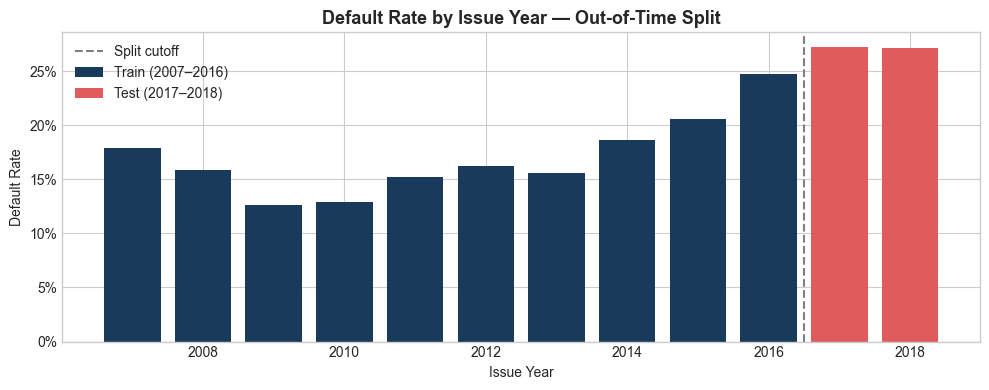

In [5]:
# Visualise default rate by year to confirm the split makes sense
default_by_year = df.groupby(SPLIT_KEY)[TARGET].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 4))

mask_train = default_by_year[SPLIT_KEY] <= TRAIN_CUTOFF
ax.bar(default_by_year.loc[mask_train,  SPLIT_KEY], default_by_year.loc[mask_train,  TARGET], color='#1a3a5c', label='Train (2007–2016)')
ax.bar(default_by_year.loc[~mask_train, SPLIT_KEY], default_by_year.loc[~mask_train, TARGET], color='#e05c5c', label='Test (2017–2018)')
ax.axvline(x=TRAIN_CUTOFF + 0.5, color='gray', linestyle='--', linewidth=1.5, label='Split cutoff')

ax.set_xlabel('Issue Year')
ax.set_ylabel('Default Rate')
ax.set_title('Default Rate by Issue Year — Out-of-Time Split', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend()
plt.tight_layout()
plt.show()

**Out-of-time split results: train 20.23% vs. test 27.20% — a 6.97 pp divergence.**

This is expected, it is the result of **loan maturity censoring**:

- **2007–2016 loans** had fully matured by the time the dataset was compiled. Both defaults *and* fully-paid loans are completely captured.
- **2017–2018 loans** had not yet matured. A 60-month loan originated in 2017 would not resolve until 2022. The cleaning pipeline removed `Current` loans (outcome unknown), so what remains in the 2017–2018 cohort are only the **fast-resolving loans** — and early defaults resolve much faster than healthy repayments that run their full term.

The consequence: the test set over-represents early defaults for recent vintages, inflating the observed default rate to 27.20%.

**What this means for model evaluation:**
- The model is trained on a 20.23% default rate and tested on 27.20% — a harder, more conservative test.
- **Discrimination metrics** (ROC-AUC, KS) will reflect performance on this harder test set — acceptable.
- **Calibration** will show the model underestimates PD for recent vintages, since it was trained on a lower base rate. This is expected and should be flagged in the model summary.
- This divergence is a known characteristic of Lending Club data and would be documented in any real-world model validation report.

---

## Redundant features

Before encoding categoricals, we check for multicollinearity — feature pairs so highly correlated that keeping both destabilizes a model's coefficients without adding predictive power. The check runs on **training data only**, matching the fit-only-on-train discipline used for the out-of-time split and the WoE encoding below.

In [6]:
GRADE_MAP = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
grade_numeric = X_train['grade'].map(GRADE_MAP)

corr_check = X_train.drop(columns=['grade', 'purpose']).assign(grade=grade_numeric)

pairs = [('grade', 'int_rate'), ('loan_amnt', 'installment'), ('total_acc', 'open_acc')]

print('=== Multicollinearity check (train only) ===')
for a, b in pairs:
    r = corr_check[a].corr(corr_check[b])
    print(f'{a:12s} vs {b:12s}: r = {r:.3f}')

=== Multicollinearity check (train only) ===
grade        vs int_rate    : r = 0.955
loan_amnt    vs installment : r = 0.954
total_acc    vs open_acc    : r = 0.699


**`grade` vs. `int_rate` (r = 0.955)** — Stage 3's EDA already showed the platform prices loans almost entirely by grade; interest rate carries little signal beyond it (Finding 4, `03_eda.ipynb`). Keeping both would destabilize a linear model's coefficients without adding predictive power. **`int_rate` is dropped, `grade` is kept** — it's the more interpretable, industry-standard risk tier, and the variable this project's story has been built around since Stage 2.

**`loan_amnt` vs. `installment` (r = 0.954)** — installment is arithmetically derived from loan amount, rate, and term (same Finding 4). **`installment` is dropped, `loan_amnt` is kept.**

**`total_acc` vs. `open_acc` (r = 0.699)** is real but softer — both are kept, since each still carries meaningful independent variance (r² ≈ 0.49, over half unexplained).

`GRADE_MAP` defined above is the single source of truth for `grade`'s numeric conversion — it is reused, not redefined, in the Preprocessing section below.

In [7]:
REDUNDANT = ['int_rate', 'installment']

X_train = X_train.drop(columns=REDUNDANT)
X_test  = X_test.drop(columns=REDUNDANT)
FEATURES = [f for f in FEATURES if f not in REDUNDANT]

print(f'Features after removing redundant pairs ({len(FEATURES)}):')
for f in FEATURES:
    print(f'  - {f}')

Features after removing redundant pairs (15):
  - grade
  - delinq_2yrs
  - inq_last_6mths
  - dti
  - annual_inc
  - revol_util
  - loan_amnt
  - term
  - purpose
  - total_acc
  - open_acc
  - mths_since_last_delinq
  - ever_delinq
  - credit_history_months
  - fico_score


---

## Preprocessing

One transformation is needed before modeling — categorical encoding:

- **`grade`** is ordinal (A → G, mapped to 1–7 via `GRADE_MAP`, defined in the previous section).
- **`purpose`** (14 categories) is Weight-of-Evidence (WoE) encoded — each category is replaced with the log-odds of default it carries, computed **only from the training set** and then applied unchanged to test. This is the encoding Stage 1 deferred to here, and it avoids the information loss a coarser grouping (or a 14-column one-hot expansion) would introduce.

`mths_since_last_delinq` needs no missing-value handling here — Stage 1 already imputed it and confirmed zero nulls remain across the full cleaned dataset. The `ever_delinq` flag (also from Stage 1) already carries the "was this borrower ever delinquent" signal directly, so nothing further is derived from it.

In [8]:
def compute_woe(y: pd.Series, categories: pd.Series) -> dict:
    """Weight of Evidence for each category, fit on this data only (train)."""
    total_events     = y.sum()
    total_non_events = len(y) - total_events

    grouped = pd.DataFrame({'cat': categories, 'target': y}).groupby('cat')['target'].agg(['sum', 'count'])
    grouped['non_events'] = grouped['count'] - grouped['sum']

    # Small smoothing avoids log(0) for any category with zero events or non-events
    pct_events     = (grouped['sum'] + 0.5) / (total_events + 0.5 * len(grouped))
    pct_non_events = (grouped['non_events'] + 0.5) / (total_non_events + 0.5 * len(grouped))

    return np.log(pct_non_events / pct_events).to_dict()


def preprocess(X: pd.DataFrame, purpose_woe_map: dict) -> pd.DataFrame:
    X = X.copy()

    # Ordinal encode grade (mapping is GRADE_MAP, defined in Redundant features)
    X['grade'] = X['grade'].map(GRADE_MAP)

    # WoE-encode purpose (map fit on train only; unseen categories fall back to neutral WoE = 0)
    X['purpose'] = X['purpose'].map(purpose_woe_map).fillna(0)

    return X


# Fit WoE strictly on train, then apply the same mapping to both splits
purpose_woe_map = compute_woe(y_train, X_train['purpose'])

X_train_p = preprocess(X_train, purpose_woe_map)
X_test_p  = preprocess(X_test,  purpose_woe_map)

print(f'Preprocessed feature count: {X_train_p.shape[1]}')
print(f'\nFinal features:')
for f in X_train_p.columns:
    print(f'  - {f}')

Preprocessed feature count: 15

Final features:
  - grade
  - delinq_2yrs
  - inq_last_6mths
  - dti
  - annual_inc
  - revol_util
  - loan_amnt
  - term
  - purpose
  - total_acc
  - open_acc
  - mths_since_last_delinq
  - ever_delinq
  - credit_history_months
  - fico_score


The preprocessed splits are saved to `data/processed/` so that the LGD and EAD notebooks reuse the same exact splits without re-running this notebook.

In [9]:
X_train_p.to_parquet('../data/processed/X_train_pd.parquet', index=False)
X_test_p.to_parquet('../data/processed/X_test_pd.parquet',   index=False)
y_train.to_frame().to_parquet('../data/processed/y_train_pd.parquet', index=False)
y_test.to_frame().to_parquet('../data/processed/y_test_pd.parquet',   index=False)

# Also save the full train/test rows (LGD notebook filters to defaulted loans only)
train.to_parquet('../data/processed/train_full.parquet', index=False)
test.to_parquet('../data/processed/test_full.parquet',   index=False)

print('Splits saved to data/processed/')

Splits saved to data/processed/


---

## Data summary

In [10]:
import os

files = {
    'X_train_pd.parquet': X_train_p,
    'X_test_pd.parquet':  X_test_p,
    'y_train_pd.parquet': y_train.to_frame(),
    'y_test_pd.parquet':  y_test.to_frame(),
    'train_full.parquet': train,
    'test_full.parquet':  test,
}

print('=== Output Files ===')
for fname, df_out in files.items():
    path = f'../data/processed/{fname}'
    size_kb = os.path.getsize(path) / 1024
    print(f'  {fname:<30} {df_out.shape[0]:>10,} rows × {df_out.shape[1]:>2} cols  |  {size_kb:,.0f} KB')

print(f'\n=== Split Verification ===')
print(f'  Train features:  {X_train_p.shape[1]} columns  |  {X_train_p.isnull().sum().sum()} nulls')
print(f'  Test features:   {X_test_p.shape[1]} columns  |  {X_test_p.isnull().sum().sum()} nulls')
print(f'  Column alignment: {"✓ identical" if list(X_train_p.columns) == list(X_test_p.columns) else "✗ MISMATCH"}')

=== Output Files ===
  X_train_pd.parquet              1,127,206 rows × 15 cols  |  13,768 KB
  X_test_pd.parquet                 243,959 rows × 15 cols  |  2,999 KB
  y_train_pd.parquet              1,127,206 rows ×  1 cols  |  170 KB
  y_test_pd.parquet                 243,959 rows ×  1 cols  |  35 KB
  train_full.parquet              1,127,206 rows × 20 cols  |  24,273 KB
  test_full.parquet                 243,959 rows × 20 cols  |  5,441 KB

=== Split Verification ===
  Train features:  15 columns  |  0 nulls
  Test features:   15 columns  |  0 nulls
  Column alignment: ✓ identical


The modeling data is ready. Four decisions were made and verified:

| Decision | Choice | Verified |
|---|---|---|
| **Leakage removal** | `total_pymnt` excluded from all features; `ever_delinq` correctly retained as a legitimate pre-origination feature | ✓ `total_pymnt` absent from `X_train_p`/`X_test_p`; `ever_delinq` present in both |
| **Out-of-time split** | Train 2007–2016 (1,127,206 loans) · Test 2017–2018 (243,959 loans) | ✓ No year overlap between splits |
| **Redundant features removed** | `int_rate` (r = 0.955 with `grade`) and `installment` (r = 0.954 with `loan_amnt`) dropped | ✓ Neither column appears in `X_train_p`/`X_test_p`; feature count reduced 17 → 15 |
| **Consistent encoding** | `preprocess()` fit-and-applied on train, applied-only on test | ✓ Column count and order identical across both splits |

**Known characteristic — default rate divergence (20.23% train vs. 27.20% test):** due to loan maturity censoring in recent vintages. Documented in the Out-of-Time Split section. All downstream models will be evaluated with this context in mind.

---

**What comes next — `06_PD_model.ipynb`**

The data preparation pipeline answered: *"Is the data ready for modeling?"* Yes. Now the modeling begins.

Stage 6 loads the preprocessed parquet splits from `data/processed/` and trains two models to predict the probability of default:
- **Logistic Regression** — interpretable scorecard baseline, the industry standard for credit risk.
- **LightGBM** — gradient boosting challenger, evaluated on the same ROC-AUC, KS statistic, and calibration criteria.

Both need to be (re)trained against this notebook's current 15-feature output — `06_PD_model.ipynb`'s existing results predate this notebook's leakage, redundant-feature, and encoding fixes, and no longer match the data it will load.